# 05 - Roteirização: agrupar entregas economiza quanto, e a que custo?

**Pergunta de negócio:** se cada moto levar vários pedidos por viagem, quantos km economizamos - e quantas entregas passam a chegar fora do prazo?

**Cenário (simulado):**
- Cada cidade tem um **hub** no bairro Centro (coordenada real do OSM).
- Os pedidos coletados na cidade são despachados em **lotes de 2 horas**; entram lotes com pelo menos 3 pedidos.
- Cada moto leva **até 4 pedidos** por viagem, sai do hub e volta a ele.
- Tempo de chegada **determinístico**: distância / velocidade média (28 km/h, ou 18 km/h no pico) + 3 min por parada anterior. O prazo é contado a partir da saída do hub (o tempo de espera do lote não entra).

**Métodos comparados** (`src/logistica_rotas/roteirizacao/`):
1. **Individual** - uma viagem de ida e volta por pedido (operação atual).
2. **Vizinho mais próximo** - heurística simples: vai sempre ao pedido mais perto.
3. **OR-Tools** - otimização (CVRP) que minimiza só a distância.
4. **OR-Tools com prazo** - minimiza distância + penalidade por minuto de atraso (1 min = 2 km).

## 1. Configuração e lotes

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ / "src"))

from logistica_rotas.ingestao.leitura import carregar_entregas
from logistica_rotas.limpeza.tratamento import CAMINHO_PROCESSED, limpar_entregas, salvar_parquet

pd.set_option("display.float_format", "{:.1f}".format)
pd.set_option("display.width", 140)

if not CAMINHO_PROCESSED.exists():  # Parquet fica fora do Git: gera a partir do CSV se faltar
    salvar_parquet(limpar_entregas(carregar_entregas()), CAMINHO_PROCESSED)
df = pd.read_parquet(CAMINHO_PROCESSED)

from logistica_rotas.roteirizacao.lotes import (
    ORDEM_METODOS, avaliar_lote, carregar_ou_calcular, hubs_por_cidade, montar_lotes, resumo_metodos,
)
from logistica_rotas.visualizacao import graficos as g
from logistica_rotas.visualizacao.mapas import mapa_rotas, salvar_mapa

lotes = montar_lotes(df)
tamanhos = lotes.groupby("lote").size()
print(f"{tamanhos.size} lotes | {len(lotes):,} entregas ({len(lotes) / (df['status'] != 'cancelado').sum():.0%} das não canceladas)"
      .replace(",", "."))
tamanhos.value_counts().sort_index().rename("lotes").to_frame().T

761 lotes | 3.246 entregas (68% das não canceladas)


,3,4,5,6,7,8,9,10,11
lotes,306,192,131,65,40,15,7,3,2


## 2. Todos os lotes

O cálculo dos 4 métodos em todos os lotes leva alguns minutos; o resultado fica salvo em `data/processed/resultados_rotas.parquet`. Use `RECALCULAR = True` para refazer.

In [2]:
RECALCULAR = False
resultados = carregar_ou_calcular(lotes, recalcular=RECALCULAR)
resumo = resumo_metodos(resultados).reindex(ORDEM_METODOS)
resumo[["entregas", "viagens", "entregas_por_viagem", "km", "km_por_entrega", "economia_km_pct",
        "no_prazo_pct", "atraso_total_min"]]

,entregas,viagens,entregas_por_viagem,km,km_por_entrega,economia_km_pct,no_prazo_pct,atraso_total_min
metodo,,,,,,,,
individual,3246,3246,1.0,30770.1,9.5,0.0,98.3,234.1
vizinho mais próximo,3246,1036,3.1,22134.8,6.8,28.1,74.9,10019.5
OR-Tools,3246,1036,3.1,20090.5,6.2,34.7,68.4,25175.7
OR-Tools com prazo,3246,1427,2.3,21842.1,6.7,29.0,96.0,355.7


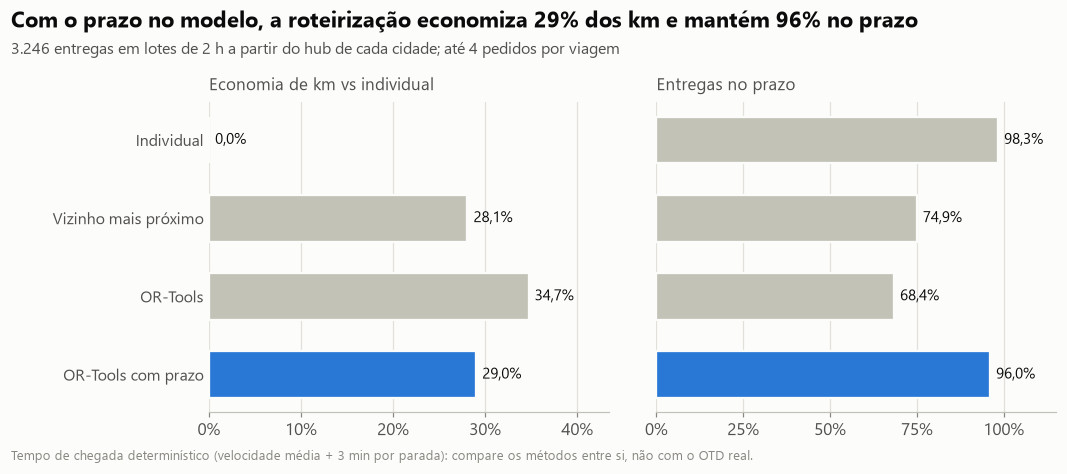

In [3]:
fig = g.comparacao_metodos(resumo)
g.salvar_figura(fig, "08_comparacao_metodos");

**Leitura:** minimizar só a distância (OR-Tools e vizinho mais próximo) junta pedidos em viagens longas - os últimos da fila estouram o prazo. Colocar o prazo no modelo abre mão de parte da economia (mais viagens), mas mantém quase todas as entregas no prazo.

## 3. Pico x fora do pico

In [4]:
por_pico = resumo_metodos(resultados, por=["pico"])[["entregas", "economia_km_pct", "no_prazo_pct", "entregas_por_viagem"]]
por_pico.rename(index={False: "fora do pico", True: "pico"}, level="pico")

entregas  economia_km_pct  no_prazo_pct  entregas_por_viagem
pico         metodo                                                                            
fora do pico individual                2537              0.0          99.6                  1.0
             vizinho mais próximo      2537             27.9          79.2                  3.1
             OR-Tools                  2537             34.3          72.4                  3.1
             OR-Tools com prazo        2537             30.3          97.6                  2.4
pico         individual                 709              0.0          93.7                  1.0
             vizinho mais próximo       709             28.6          59.7                  3.1
             OR-Tools                   709             36.2          54.0                  3.1
             OR-Tools com prazo         709             24.0          90.1                  1.8

## 4. Tamanho do lote

In [5]:
resultados["tamanho_lote"] = pd.cut(resultados["entregas"], [2, 3, 4, 6, 99], labels=["3", "4", "5-6", "7+"])
por_tamanho = resumo_metodos(resultados, por=["tamanho_lote"])
por_tamanho = por_tamanho[por_tamanho.index.get_level_values("metodo") != "individual"]
por_tamanho[["entregas", "economia_km_pct", "no_prazo_pct"]].unstack("metodo").round(1)

entregas                                  economia_km_pct                                     no_prazo_pct  \
metodo       vizinho mais próximo OR-Tools OR-Tools com prazo vizinho mais próximo OR-Tools OR-Tools com prazo vizinho mais próximo   
tamanho_lote                                                                                                                          
3                             918      918                918                 24.2     25.9               21.8                 80.1   
4                             768      768                768                 30.9     33.8               27.4                 68.8   
5-6                          1045     1045               1045                 24.9     38.5               32.5                 77.8   
7+                            515      515                515                 36.8     44.8               37.9                 69.1   

                                          
metodo       OR-Tools OR-Tools com prazo  
tamanho_lote                              
3                73.1               96.7  
4                60.3               95.3  
5-6              71.9               96.4  
7+               64.9               95.0

**Leitura:** quanto maior o lote, mais opções de combinar pedidos próximos - nos dois OR-Tools a economia cresce com o tamanho do lote, e o OR-Tools com prazo mantém cerca de 95% no prazo em todos os tamanhos. A heurística do vizinho mais próximo não segue esse padrão: ela não "enxerga" o lote inteiro.

## 5. Um lote de exemplo

Escolhemos um lote de pico com 7 a 9 pedidos em que a diferença de prazo entre os dois OR-Tools é grande, para ver na prática o que acontece.

In [6]:
pivot = resultados.pivot_table(index=["lote", "entregas", "pico"], columns="metodo", values="no_prazo").reset_index()
candidatos = pivot[pivot["pico"] & pivot["entregas"].between(7, 9)].copy()
candidatos["ganho_prazo"] = candidatos["OR-Tools com prazo"] - candidatos["OR-Tools"]
id_exemplo = int(candidatos.sort_values(["ganho_prazo", "lote"], ascending=[False, True])["lote"].iloc[0])
lote = lotes[lotes["lote"] == id_exemplo]
hub = tuple(hubs_por_cidade().loc[lote["cidade_hub"].iloc[0]])
exemplo = avaliar_lote(lote, hubs_por_cidade())
print(f"Lote {id_exemplo}: {lote['cidade_hub'].iloc[0]}, {lote['janela'].iloc[0]:%d/%m %Hh}, {len(lote)} pedidos")
lote[["id_pedido", "local_destino", "distancia_km", "prazo_prometido_min"]]

Lote 671: São Bernardo do Campo, 23/10 18h, 8 pedidos


,id_pedido,local_destino,distancia_km,prazo_prometido_min
4336,PED004337,Ferrazópolis · SBC,3.2,20
4338,PED004339,Bairro Jardim · SA,10.0,40
4339,PED004340,Assunção · SBC,1.2,20
4341,PED004342,Assunção · SBC,4.2,25
4342,PED004343,Baeta Neves · SBC,5.6,30
4343,PED004344,Oswaldo Cruz · SCS,9.6,40
4344,PED004345,Jardim do Mar · SBC,2.0,20
4345,PED004346,Jardim do Mar · SBC,1.9,20


In [7]:
prazos = lote["prazo_prometido_min"].to_numpy()
pd.DataFrame({r.metodo: {"km": r.km_total, "viagens": len(r.rotas), "no prazo": int((r.chegada_min <= prazos).sum()),
                         "atraso total (min)": float(np.clip(r.chegada_min - prazos, 0, None).sum())}
              for r in exemplo}).T

,km,viagens,no prazo,atraso total (min)
individual,77.0,8.0,8.0,0.0
vizinho mais próximo,41.1,2.0,3.0,58.3
OR-Tools,39.5,2.0,3.0,110.5
OR-Tools com prazo,60.8,5.0,8.0,0.0


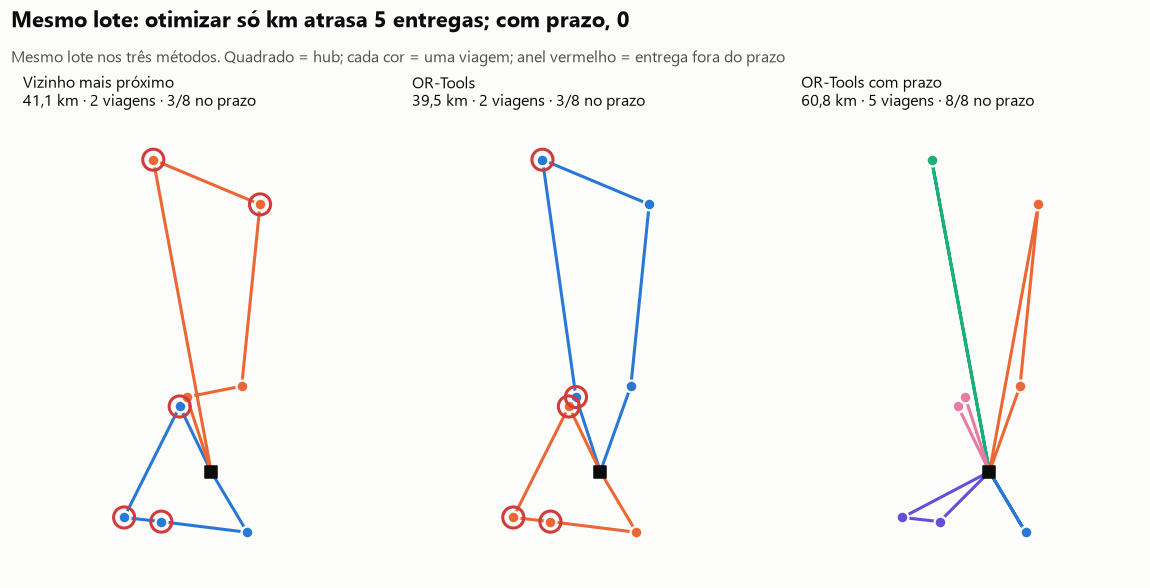

In [8]:
titulo = (f"Mesmo lote: otimizar só km atrasa {int((exemplo[2].chegada_min > prazos).sum())} entregas; "
          f"com prazo, {int((exemplo[3].chegada_min > prazos).sum())}")
fig = g.exemplo_rotas(hub, lote["lat_destino"].to_numpy(), lote["lon_destino"].to_numpy(), prazos, exemplo[1:], titulo)
g.salvar_figura(fig, "09_exemplo_rotas");

In [9]:
mapa = mapa_rotas(hub, lote["lat_destino"].to_numpy(), lote["lon_destino"].to_numpy(), exemplo[3].rotas,
                  titulo=f"OR-Tools com prazo · lote {id_exemplo} ({lote['cidade_hub'].iloc[0]})")
salvar_mapa(mapa, "mapa_rotas_exemplo")
mapa

## 6. Conclusões

**Conclusões:**
1. **Minimizar só a distância não serve.** O OR-Tools sozinho economiza 34,7% dos km, mas só 68,4% das entregas chegam no prazo. O vizinho mais próximo fica em 28,1% de economia e 74,9% no prazo. Agrupar pedidos sem olhar o prazo deixa os últimos da fila esperando.
2. **Com o prazo no modelo, a troca vale a pena.** O OR-Tools com prazo economiza 29,0% dos km (cerca de 8,9 mil km a menos em dois meses) e usa 56% menos viagens (1.427 contra 3.246). Ele mantém 96,0% no prazo, contra 98,3% das viagens individuais.
3. **No pico, o modelo se adapta.** Ele agrupa menos (1,8 entrega por viagem, contra 2,4 fora do pico), e a economia cai para 24,0% com 90,1% no prazo. É o mesmo efeito do notebook 03: no pico, a folga do prazo acaba mais rápido.
4. **Lotes maiores rendem mais.** No OR-Tools com prazo, a economia vai de 21,8% em lotes de 3 pedidos a 37,9% em lotes de 7 ou mais, sem perder prazo.
5. **No exemplo** (São Bernardo, 23/10 às 18h, 8 pedidos), otimizar só os km gera 39,5 km com 5 entregas atrasadas. Com prazo, são 60,8 km e nenhum atraso. As viagens individuais somariam 77,0 km.

**Limitações:**
- Os hubs são hipotéticos (no Centro de cada cidade). A velocidade é média e fixa, e o tempo de espera do lote não entra no prazo.
- A distância é em linha reta multiplicada por 1,3, e não a rota real pela malha viária.
- A penalidade (1 min de atraso = 2 km) e a capacidade (4 pedidos) foram escolhidas sem teste. Um estudo de sensibilidade mostraria como a economia muda com elas.

**Próximos passos:**
1. Sensibilidade da penalidade, da capacidade e do tamanho da janela (1 h ou 2 h).
2. Distância e tempo reais pela malha viária, por exemplo com o OSRM (exige serviço externo ou um servidor próprio).
3. Considerar o tempo de espera do lote no prazo (janela de despacho).
